<a href="https://colab.research.google.com/github/DilemmaFixer3/MZKN_labs/blob/main/Lab_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Завантаження даних та первинний аудит
(Огляд розмірності, типів даних та пошук пропусків)

In [4]:
import pandas as pd
import numpy as np

# 1. Зчитуємо файл
df = pd.read_csv("data1.csv")

# 2. Перевірка розмірності та типів даних
print("=== Інформація про датасет ===")
df.info()

print("\n=== Кількість пропусків у кожній колонці ===")
print(df.isna().sum())

print("\n=== Перші 5 рядків сирих даних ===")
df.head()

=== Інформація про датасет ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   age      184 non-null    float64
 1   income   191 non-null    float64
 2   score    184 non-null    float64
 3   city     189 non-null    object 
 4   segment  186 non-null    object 
dtypes: float64(3), object(2)
memory usage: 7.9+ KB

=== Кількість пропусків у кожній колонці ===
age        16
income      9
score      16
city       11
segment    14
dtype: int64

=== Перші 5 рядків сирих даних ===


,age,income,score,city,segment
0,22.0,60996.61,NaN,Lviv,B
1,58.0,41417.81,41.69,Lviv,B
2,52.0,49327.56,23.26,Ivano-Frankivsk,NaN
3,40.0,74488.42,36.75,Ivano-Frankivsk,B
4,40.0,49656.04,36.64,Ivano-Frankivsk,B


# Заповнення пропусків
(Числові ознаки age, income, score заповнюємо середнім, а категоріальну city — модою)

In [5]:
from sklearn.impute import SimpleImputer

# Копіюємо DataFrame для безпечної обробки
df_imputed = df.copy()

# 1. Заповнення числових пропусків середнім значенням
num_cols = ["age", "income", "score"]
num_imputer = SimpleImputer(strategy="mean")
df_imputed[num_cols] = num_imputer.fit_transform(df_imputed[num_cols])

# 2. Заповнення категоріальних пропусків найчастішим значенням (модою)
cat_cols = ["city", "segment"]
cat_imputer = SimpleImputer(strategy="most_frequent")
df_imputed[cat_cols] = cat_imputer.fit_transform(df_imputed[cat_cols])

print("=== Перевірка залишків пропусків ===")
print(df_imputed.isna().sum())

=== Перевірка залишків пропусків ===
age        0
income     0
score      0
city       0
segment    0
dtype: int64


Нормалізація всіх числових ознак (MinMaxScaler)
(Приводимо age, income та score до діапазону [0, 1])

In [6]:
from sklearn.preprocessing import MinMaxScaler

df_scaled = df_imputed.copy()

# Нормалізуємо всі числові атрибути (включаючи вік)
num_cols = ["age", "income", "score"]
scaler = MinMaxScaler(feature_range=(0, 1))

df_scaled[num_cols] = scaler.fit_transform(df_scaled[num_cols])

print("=== Описові статистики після нормалізації всіх числових ознак ===")
df_scaled[num_cols].describe().round(3)

=== Описові статистики після нормалізації всіх числових ознак ===


,age,income,score
count,200.000,200.000,200.000
mean,0.503,0.462,0.526
std,0.273,0.180,0.273
min,0.000,0.000,0.000
25%,0.289,0.336,0.311
50%,0.503,0.460,0.526
75%,0.725,0.545,0.749
max,1.000,1.000,1.000


Кодування категоріальних ознак (One-Hot Encoding)

In [7]:
# Кодуємо city та segment у двійкові стовпчики
df_encoded = pd.get_dummies(df_scaled, columns=["city", "segment"], dtype=float)

print(f"Нова розмірність датасету: {df_encoded.shape}")
print("\n=== Перші 5 рядків підготовленого датасету ===")
df_encoded.head()

Нова розмірність датасету: (200, 10)

=== Перші 5 рядків підготовленого датасету ===


,age,income,score,city_Ivano-Frankivsk,city_Kyiv,city_Lviv,city_Ternopil,segment_A,segment_B,segment_C
0,0.078431,0.541268,0.526110,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.784314,0.303106,0.414109,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.666667,0.399323,0.228640,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.431373,0.705387,0.364396,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.431373,0.403318,0.363289,1.0,0.0,0.0,0.0,0.0,1.0,0.0


Візуалізація розподілу 3 основних ознак до і після нормалізації

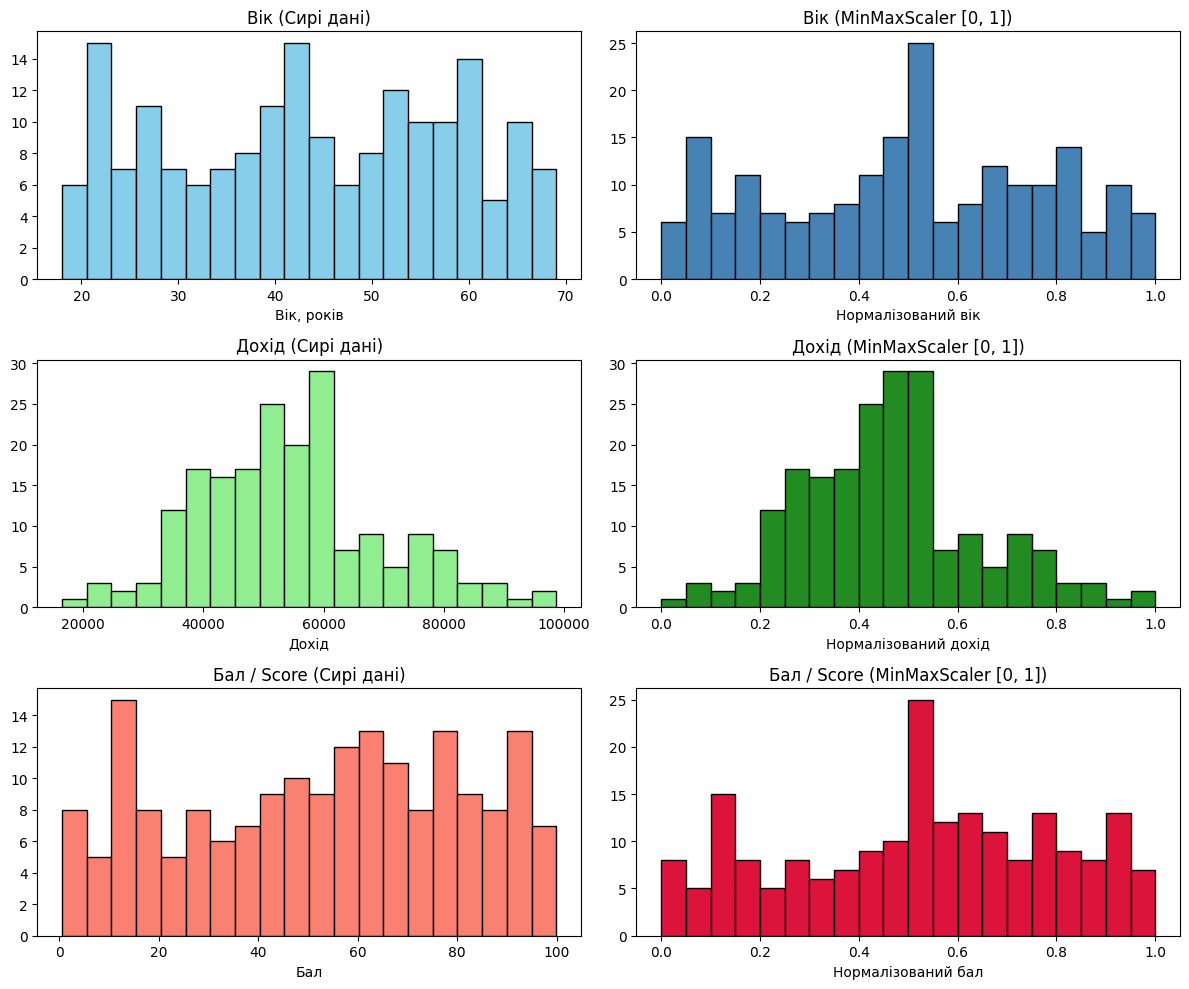

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

# 1. Вік (age)
axes[0, 0].hist(df["age"].dropna(), bins=20, color="skyblue", edgecolor="black")
axes[0, 0].set_title("Вік (Сирі дані)")
axes[0, 0].set_xlabel("Вік, років")

axes[0, 1].hist(df_encoded["age"], bins=20, color="steelblue", edgecolor="black")
axes[0, 1].set_title("Вік (MinMaxScaler [0, 1])")
axes[0, 1].set_xlabel("Нормалізований вік")

# 2. Дохід (income)
axes[1, 0].hist(df["income"].dropna(), bins=20, color="lightgreen", edgecolor="black")
axes[1, 0].set_title("Дохід (Сирі дані)")
axes[1, 0].set_xlabel("Дохід")

axes[1, 1].hist(df_encoded["income"], bins=20, color="forestgreen", edgecolor="black")
axes[1, 1].set_title("Дохід (MinMaxScaler [0, 1])")
axes[1, 1].set_xlabel("Нормалізований дохід")

# 3. Бал (score)
axes[2, 0].hist(df["score"].dropna(), bins=20, color="salmon", edgecolor="black")
axes[2, 0].set_title("Бал / Score (Сирі дані)")
axes[2, 0].set_xlabel("Бал")

axes[2, 1].hist(df_encoded["score"], bins=20, color="crimson", edgecolor="black")
axes[2, 1].set_title("Бал / Score (MinMaxScaler [0, 1])")
axes[2, 1].set_xlabel("Нормалізований бал")

plt.tight_layout()
plt.show()

Збірка у Pipeline та збереження у файл

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Редагування для всіх числових ознак (імпутація середнім + MinMaxScaler)
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler(feature_range=(0, 1)))
])

# Редагування для категоріальних ознак (імпутація модою + One-Hot)
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, ["age", "income", "score"]),
    ('cat', cat_pipeline, ["city", "segment"])
])

# Виконуємо трансформацію та зберігаємо результат
X_final = preprocessor.fit_transform(df)
columns = preprocessor.get_feature_names_out()

df_cleaned = pd.DataFrame(X_final, columns=columns)
df_cleaned.to_csv("cleaned_data1.csv", index=False)

print("Очищений файл успішно збережено у 'cleaned_data1.csv'!")


Очищений файл успішно збережено у 'cleaned_data1.csv'!


In [14]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# 1. Завантаження сирих даних
df_raw = pd.read_csv("data1.csv")

# 2. Визначення груп колонок
num_cols = ["age", "income", "score"]
cat_cols = ["city", "segment"]

# 3. Створення конвеєра (Pipeline) для числових ознак
num_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", MinMaxScaler(feature_range=(0, 1))),
    ]
)

# 4. Створення конвеєра (Pipeline) для категоріальних ознак
cat_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        ),
    ]
)

# 5. Об'єднання у ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ]
)

# 6. Обробка даних ОДНІЄЮ командою fit_transform
X_cleaned = preprocessor.fit_transform(df_raw)

# Отримання нових назв колонок після One-Hot кодування
feature_names = preprocessor.get_feature_names_out()

# Створення підсумкового очищеного DataFrame
df_cleaned = pd.DataFrame(X_cleaned, columns=feature_names)

print(
    "Застосування Pipeline завершено успішно! Розмірність:", df_cleaned.shape
)

# 1. Збереження очищеного набору даних
output_filename = "cleaned_data1.csv"
df_cleaned.to_csv(output_filename, index=False)
print(f"Файл '{output_filename}' успішно збережено.")

# 2. Перевірка завантаження без помилок
try:
    df_loaded = pd.read_csv(output_filename)
    print("\n=== ПЕРЕВІРКА ЗАВАНТАЖЕННЯ ===")
    print(f"Файл успішно прочитано!")
    print(f"Розмірність завантаженої таблиці: {df_loaded.shape}")
    print(f"Кількість пропусків у файлі: {df_loaded.isna().sum().sum()}")
    print("\nПерші 3 рядки зчитаного файлу:")
    display(df_loaded.head(3))
except Exception as e:
    print(f"Помилка при завантаженні файлу: {e}")


Застосування Pipeline завершено успішно! Розмірність: (200, 10)
Файл 'cleaned_data1.csv' успішно збережено.

=== ПЕРЕВІРКА ЗАВАНТАЖЕННЯ ===
Файл успішно прочитано!
Розмірність завантаженої таблиці: (200, 10)
Кількість пропусків у файлі: 0

Перші 3 рядки зчитаного файлу:


,num__age,num__income,num__score,cat__city_Ivano-Frankivsk,cat__city_Kyiv,cat__city_Lviv,cat__city_Ternopil,cat__segment_A,cat__segment_B,cat__segment_C
0,0.078431,0.541268,0.526110,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.784314,0.303106,0.414109,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.666667,0.399323,0.228640,1.0,0.0,0.0,0.0,0.0,1.0,0.0
